In [2]:
# Import necessary libraries
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
import random
from tensorflow.keras.preprocessing.image import ImageDataGenerator


Matplotlib is building the font cache; this may take a moment.


In [3]:
np.random.seed(12049)

In [3]:
# Define dataset paths and class names
base_dir = "E:\\AI Project\\osteoathritis_project\\dataset"
class_names = ['0', '1', '2', '3', '4']

# Paths for train, validation, and test data
train_path = os.path.join(base_dir, 'train')
val_path = os.path.join(base_dir, 'val')
test_path = os.path.join(base_dir, 'test')

# Output paths for split data
output_train_path = os.path.join(base_dir, 'train_split')
output_test_path = os.path.join(base_dir, 'test_split')

# Ensure output directories exist
os.makedirs(output_train_path, exist_ok=True)
os.makedirs(output_test_path, exist_ok=True)
target_size = (224, 224) 
batch_size = 32

In [5]:
#Define the function to split data
def split_data(src_dir, output_train_dir, output_test_dir, class_names, split_ratio=0.8):
    for class_name in class_names:
        class_dir = os.path.join(src_dir, class_name)
        images = os.listdir(class_dir)
        random.shuffle(images)
        
        split_point = int(split_ratio * len(images))
        train_images = images[:split_point]
        test_images = images[split_point:]
        
        output_train_class_dir = os.path.join(output_train_dir, class_name)
        output_test_class_dir = os.path.join(output_test_dir, class_name)
        
        os.makedirs(output_train_class_dir, exist_ok=True)
        os.makedirs(output_test_class_dir, exist_ok=True)
        
        for image in train_images:
            shutil.copy(os.path.join(class_dir, image), output_train_class_dir)
        
        for image in test_images:
            shutil.copy(os.path.join(class_dir, image), output_test_class_dir)


In [6]:

split_data(train_path, output_train_path, output_test_path, class_names, split_ratio=0.8)


In [7]:
#List directories to verify existence
print("Directories in 'train':", os.listdir(train_path))
print("Directories in 'val':", os.listdir(val_path))
print("Directories in 'test':", os.listdir(test_path))


Directories in 'train': ['0', '1', '2', '3', '4']
Directories in 'val': ['0', '1', '2', '3', '4']
Directories in 'test': ['0', '1', '2', '3', '4']


In [8]:
def count_images_in_dir(directory):
    count = {}
    for grade in range(len(class_names)):
        grade_dir = os.path.join(directory, str(grade))
        if os.path.exists(grade_dir):
            count[class_names[grade]] = len(os.listdir(grade_dir))
        else:
            count[class_names[grade]] = 0
    return count

print("Train Data Distribution:", count_images_in_dir(output_train_path))
print("Test Data Distribution:", count_images_in_dir(output_test_path))
print("Validation Data Distribution:", count_images_in_dir(val_path))


Train Data Distribution: {'0': 2315, '1': 1064, '2': 1558, '3': 777, '4': 177}
Test Data Distribution: {'0': 1139, '1': 530, '2': 757, '3': 380, '4': 83}
Validation Data Distribution: {'0': 328, '1': 153, '2': 212, '3': 106, '4': 27}


In [9]:
# Visualize a few samples from the test dataset
def get_classes(data_path, class_names, dataset_type):
    stats = {}
    for class_name in class_names:
        class_dir = os.path.join(data_path, class_name)
        stats[class_name] = len(os.listdir(class_dir))
    return {dataset_type: stats}

train_data = get_classes(output_train_path, class_names, 'Train')
val_data = get_classes(val_path, class_names, 'Valid')
test_data = get_classes(output_test_path, class_names, 'Test')

print('Train Data:', train_data)
print('Validation Data:', val_data)
print('Test Data:', test_data)



Train Data: {'Train': {'0': 2315, '1': 1064, '2': 1558, '3': 777, '4': 177}}
Validation Data: {'Valid': {'0': 328, '1': 153, '2': 212, '3': 106, '4': 27}}
Test Data: {'Test': {'0': 1139, '1': 530, '2': 757, '3': 380, '4': 83}}


In [10]:
#Define the get_classes function
def get_classes(data_path, classes, data):
    print(f"---- {data} ----")
    knee_severity = {}
    count = 0

    for i in range(len(classes)):
        imgs = os.listdir(os.path.join(data_path, str(i)))
        knee_severity[i] = imgs
        count += len(imgs)

    for k, v in knee_severity.items():
        print(f"Grade {k} - {classes[k]}: {len(v)} images, {round((len(v) * 100) / count, 2)}%")

    return knee_severity


In [7]:
# plot_classes function
def plot_classes(dict_classes, data_path, classes, data):
    severity_labels = {
        0: 'Healthy',
        1: 'Doubtful',
        2: 'Minimal',
        3: 'Moderate',
        4: 'Severe'
    }
    
    for k, v in dict_classes.items():
        print(f"{data} - {classes[k]}")
        plt.figure(figsize=(15, 5))
        for i in range(min(1, len(v))):
            img_path = os.path.join(data_path, str(k), v[i])
            img = tf.keras.preprocessing.image.load_img(img_path)
            plt.subplot(1, 5, 1 + i, xticks=[], yticks=[])
            plt.imshow(img)
            plt.title(f"Grade {k}: {severity_labels[k]}")
        plt.suptitle(f"{data} - Grade {k}: {severity_labels[k]}", fontsize=16)
        plt.show()


In [12]:
#Display the dataset statistics using get_classes
train_data = get_classes(output_train_path, class_names, 'Train')
val_data = get_classes(val_path, class_names, 'Valid')
test_data = get_classes(output_test_path, class_names, 'Test')

print('Train Data:', train_data)
print('Validation Data:', val_data)
print('Test Data:', test_data)


---- Train ----
Grade 0 - 0: 2315 images, 39.3%
Grade 1 - 1: 1064 images, 18.06%
Grade 2 - 2: 1558 images, 26.45%
Grade 3 - 3: 777 images, 13.19%
Grade 4 - 4: 177 images, 3.0%
---- Valid ----
Grade 0 - 0: 328 images, 39.71%
Grade 1 - 1: 153 images, 18.52%
Grade 2 - 2: 212 images, 25.67%
Grade 3 - 3: 106 images, 12.83%
Grade 4 - 4: 27 images, 3.27%
---- Test ----
Grade 0 - 0: 1139 images, 39.43%
Grade 1 - 1: 530 images, 18.35%
Grade 2 - 2: 757 images, 26.2%
Grade 3 - 3: 380 images, 13.15%
Grade 4 - 4: 83 images, 2.87%
Train Data: {0: ['9001695L.png', '9001897L.png', '9003126L.png', '9003126R.png', '9003175L.png', '9003175R.png', '9003430L.png', '9003658L.png', '9003658R.png', '9003815R.png', '9004184R.png', '9004315L.png', '9004315R.png', '9004669R.png', '9005075L.png', '9005075R.png', '9005321L.png', '9005321R.png', '9005656L.png', '9005656R.png', '9006407L.png', '9007904L.png', '9007904R.png', '9008820L.png', '9009623L.png', '9009623R.png', '9009957L.png', '9010308L.png', '9010308R.pn

Train - 0


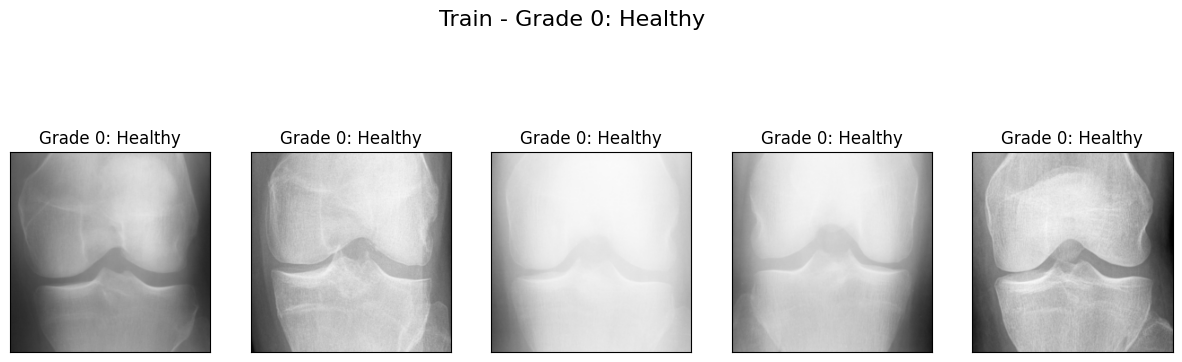

Train - 1


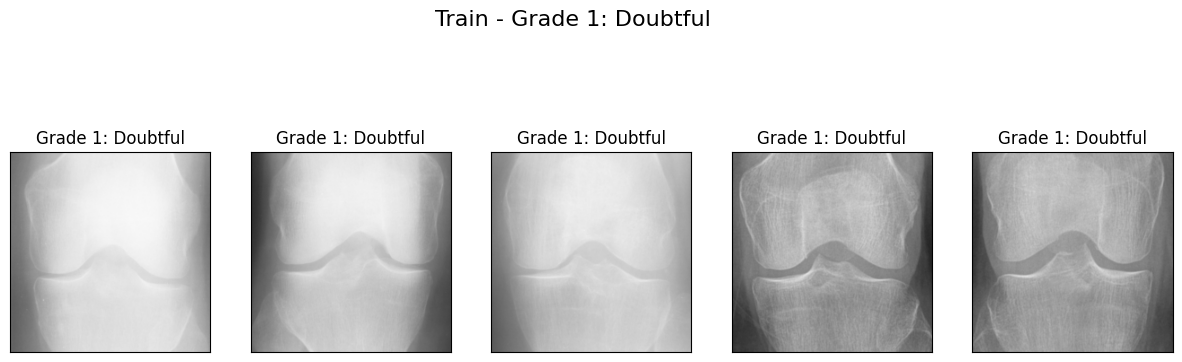

Train - 2


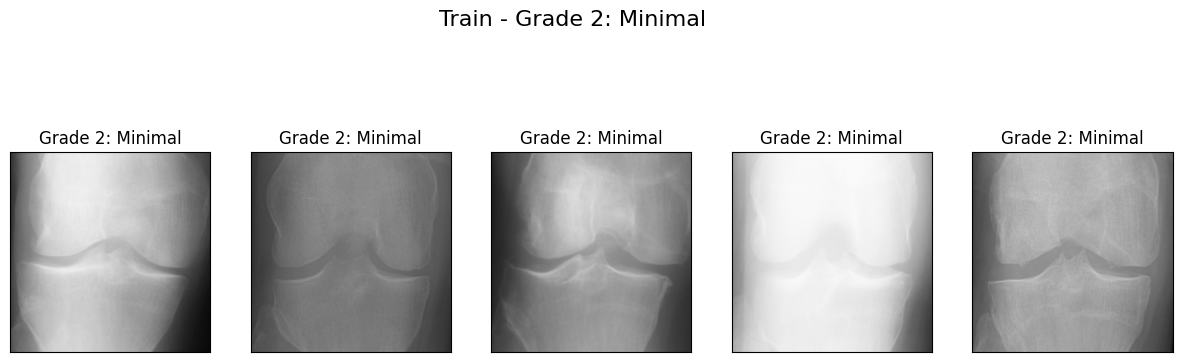

Train - 3


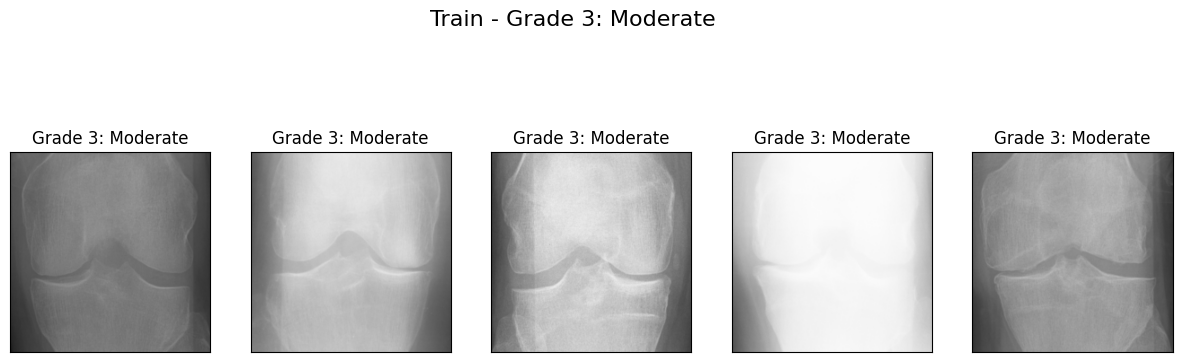

Train - 4


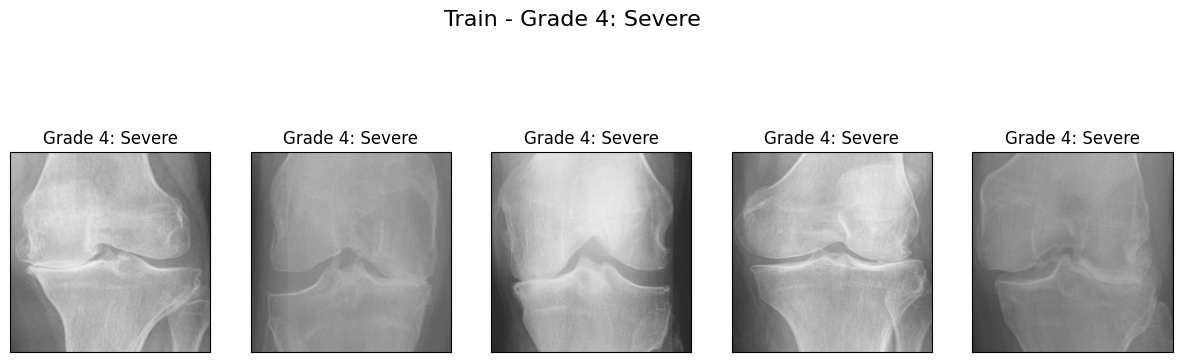

In [13]:
# Cell 9: Plot sample images from the train dataset using plot_classes
plot_classes(train_data, output_train_path, class_names, 'Train')


Test - 0


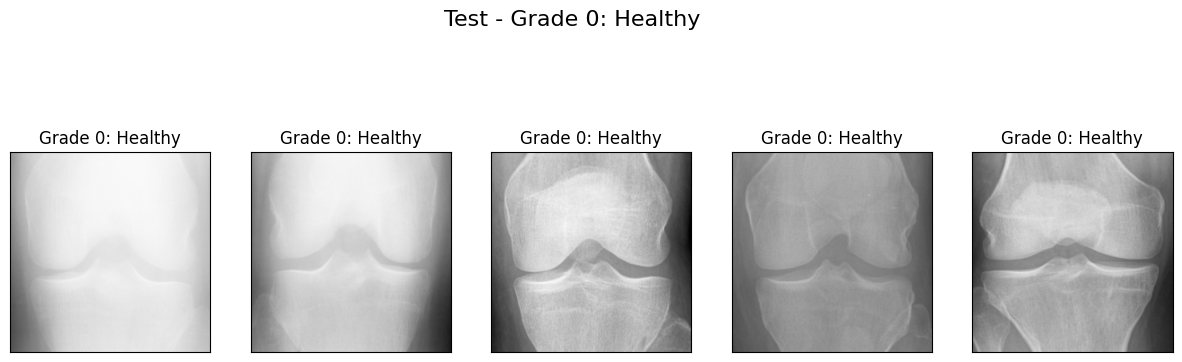

Test - 1


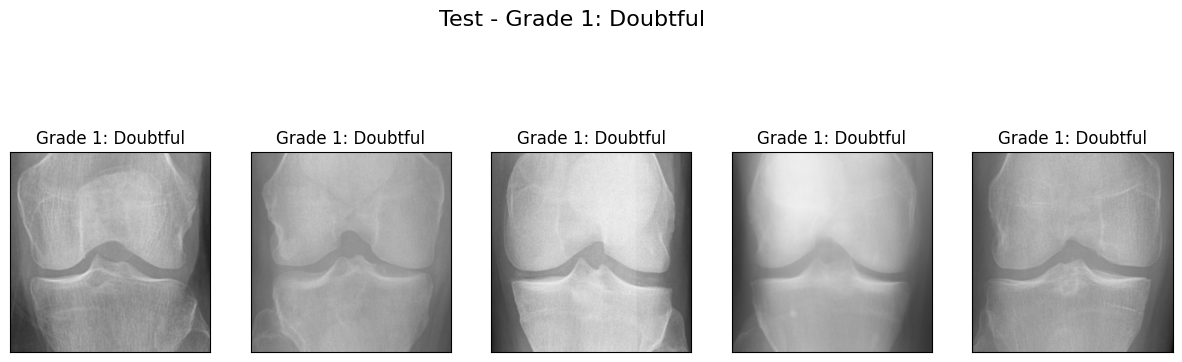

Test - 2


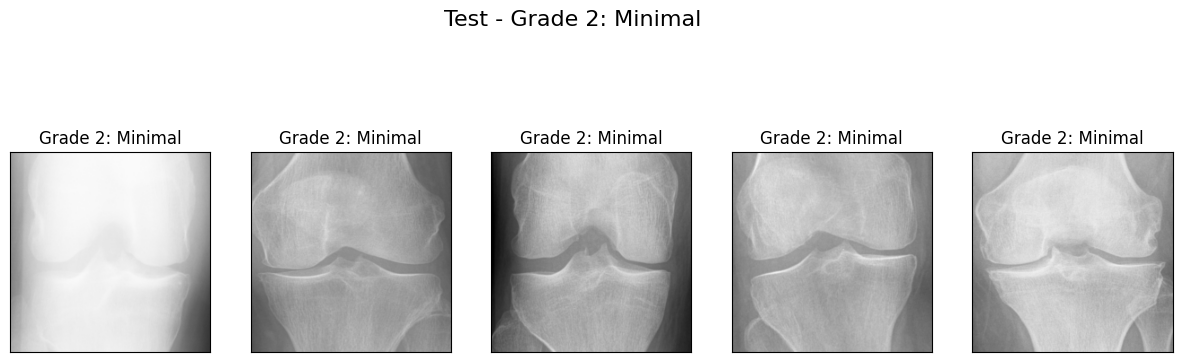

Test - 3


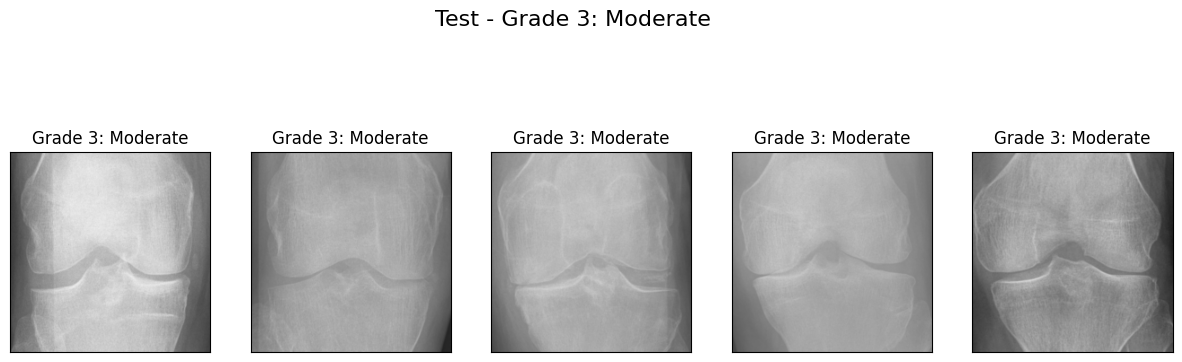

Test - 4


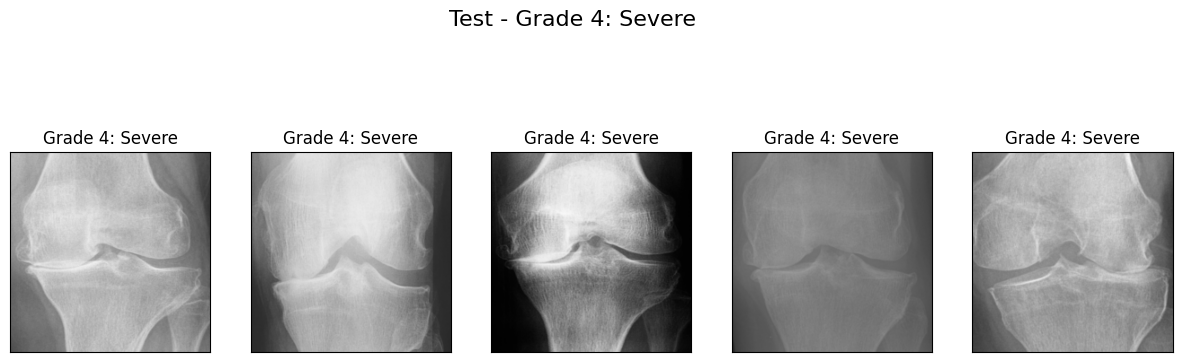

In [14]:
#Plot sample images from the test dataset using plot_classes
plot_classes(test_data, output_test_path, class_names, 'Test')


Valid - 0


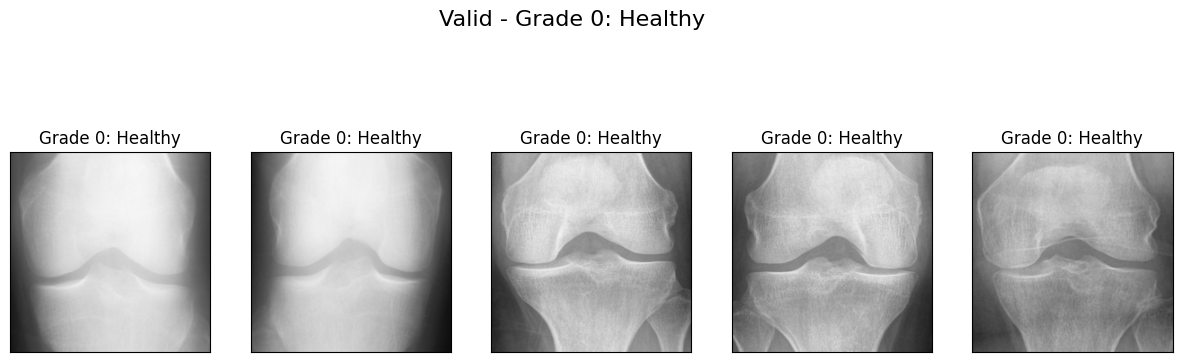

Valid - 1


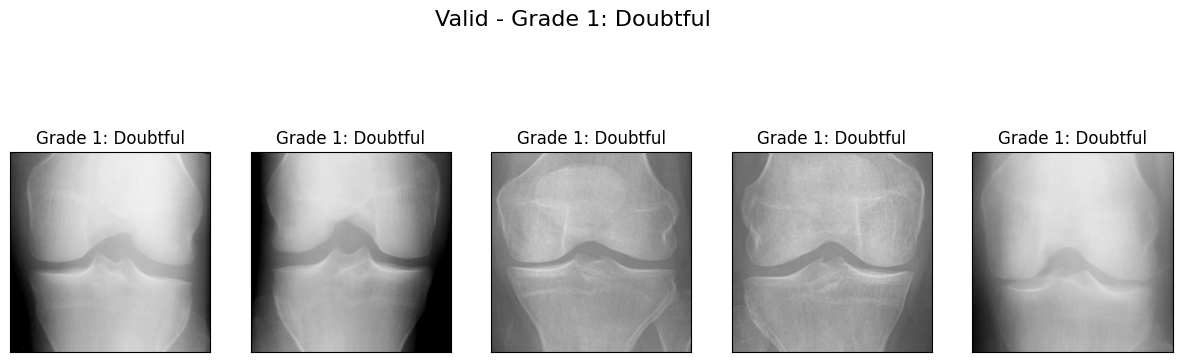

Valid - 2


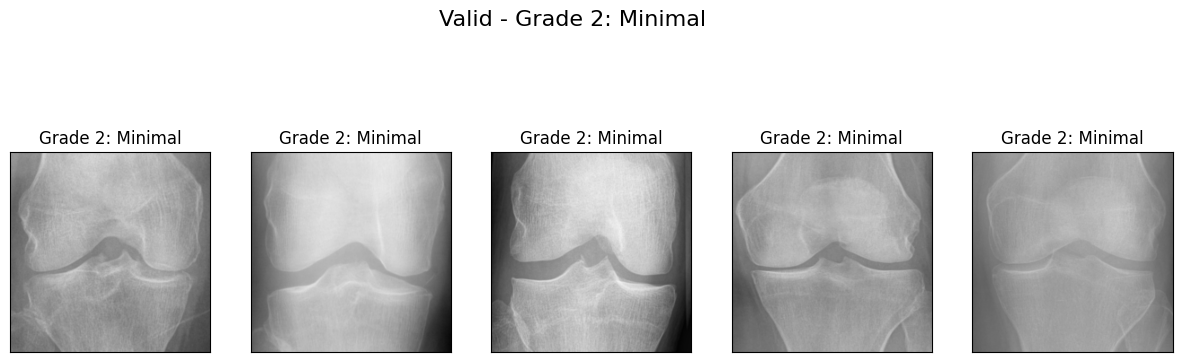

Valid - 3


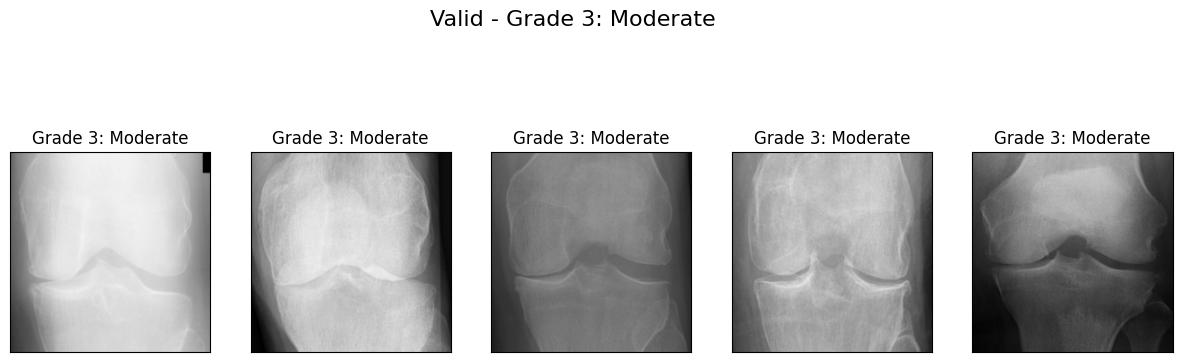

Valid - 4


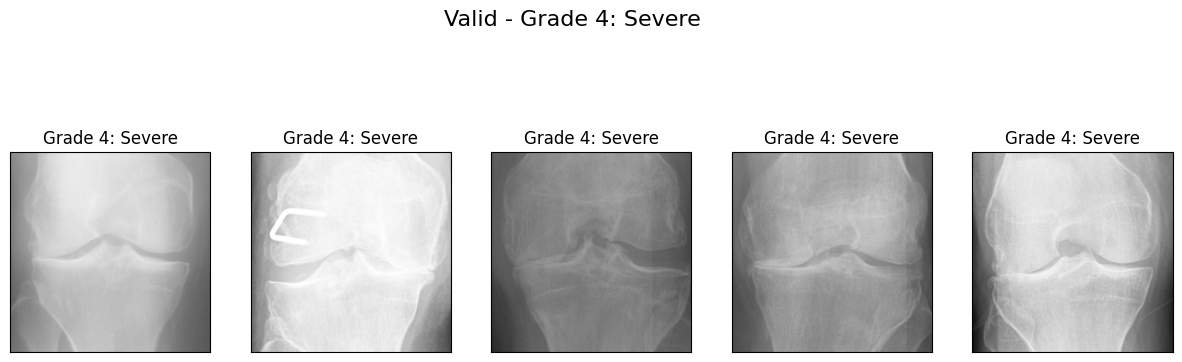

In [15]:
#Plot sample images from the validation dataset using plot_classes
plot_classes(val_data, val_path, class_names, 'Valid')


In [9]:
# Cell 2: Define ImageDataGenerators
aug_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.resnet50.preprocess_input,
    horizontal_flip=True,
    brightness_range=[0.3, 0.8],
    width_shift_range=[-50, 0, 50, 30, -30],
    zoom_range=0.1,
    fill_mode="nearest",
)

noaug_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.resnet50.preprocess_input,
)


In [10]:
#Set up image generators
train_generator = aug_datagen.flow_from_directory(
    train_path, 
    class_mode="categorical", 
    target_size=target_size, 
    batch_size=batch_size, 
    shuffle=True
)

valid_generator = noaug_datagen.flow_from_directory(
    val_path,
    class_mode="categorical",
    target_size=target_size,
    batch_size=batch_size,
    shuffle=False,
)


Found 5946 images belonging to 5 classes.
Found 826 images belonging to 5 classes.


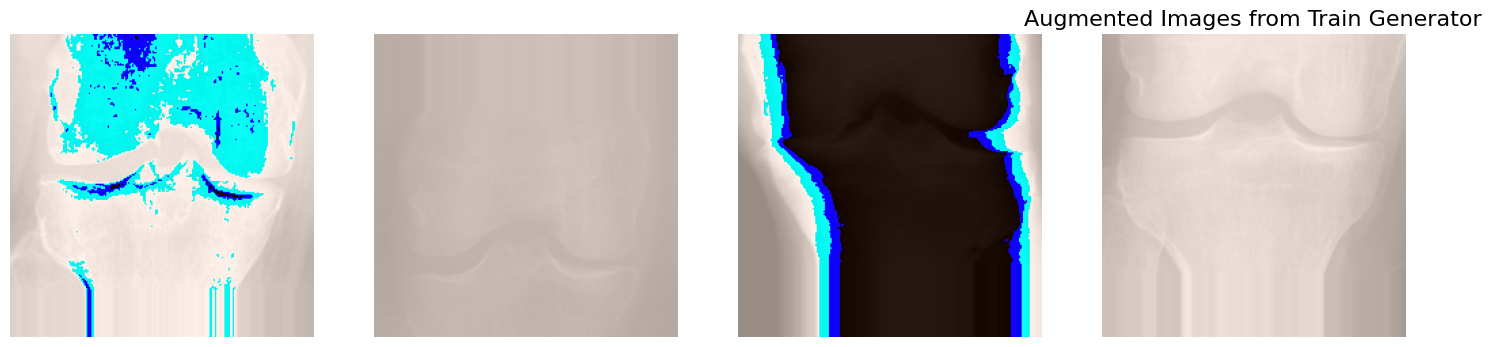

In [13]:
# Cell 4: Visualize augmented images
def plot_augmented_images(generator, title):
    x_batch, y_batch = next(generator)
    fig, axes = plt.subplots(1, 4, figsize=(18, 18))
    for i in range(4):
        axes[i].imshow(x_batch[i].astype("uint8"))
        axes[i].axis('off')
    plt.title(title, fontsize=16)
    plt.show()

plot_augmented_images(train_generator, "Augmented Images from Train Generator")


In [19]:
# Define brightness augmentation
datagen_brightness = ImageDataGenerator(brightness_range=[0.3, 0.8])
imagegen_brightness = datagen_brightness.flow_from_directory(train_path, target_size=target_size, batch_size=1)


Found 5946 images belonging to 5 classes.


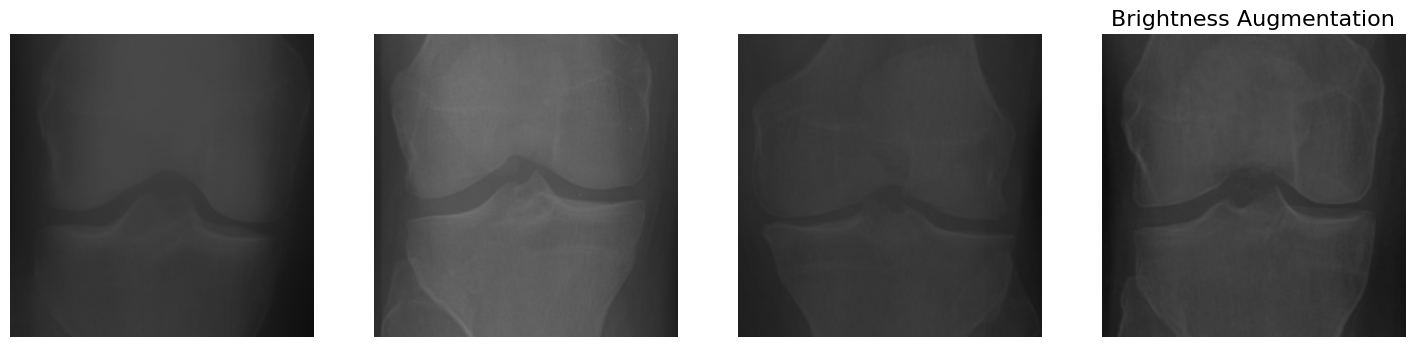

In [20]:
# Cell 3: Visualize brightness augmentation
fig, rows = plt.subplots(1, 4, figsize=(18, 18))
plt.title("Brightness Augmentation", fontsize=16)
for row in rows:
    row.imshow(imagegen_brightness.__next__()[0][0].astype("uint8"))
    row.axis('off')
plt.show()


In [21]:
# Cell 4: Define width shift augmentation
datagen_width_shift = ImageDataGenerator(width_shift_range=0.2)
imagegen_width_shift = datagen_width_shift.flow_from_directory(train_path, target_size=target_size, batch_size=1)



Found 5946 images belonging to 5 classes.


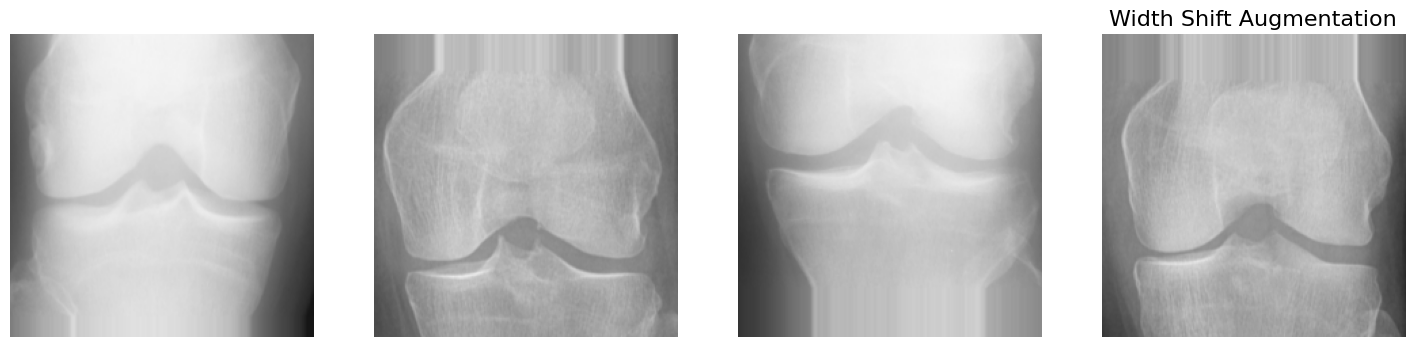

In [22]:
# Cell 5: Visualize width shift augmentation
# Width Shift Augmentation: Randomly shifts the images horizontally by a fraction of the total width.
fig, rows = plt.subplots(1, 4, figsize=(18, 18))
plt.title("Width Shift Augmentation", fontsize=16)
for row in rows:
    row.imshow(imagegen_width_shift.__next__()[0][0].astype("uint8"))
    row.axis('off')
plt.show()


In [23]:
# Cell 6: Define height shift augmentation
datagen_height_shift = ImageDataGenerator(height_shift_range=0.2)
imagegen_height_shift = datagen_height_shift.flow_from_directory(train_path, target_size=target_size, batch_size=1)


Found 5946 images belonging to 5 classes.


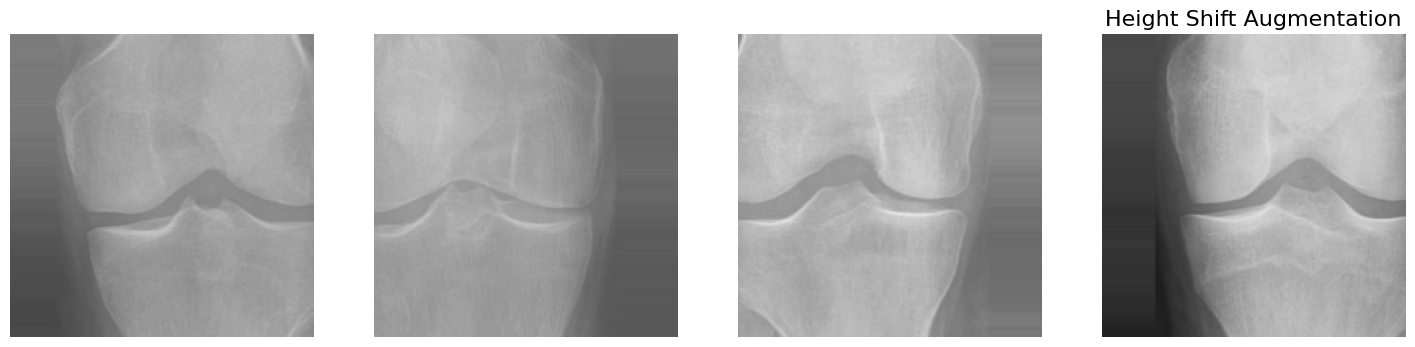

In [24]:
# Cell 7: Visualize height shift augmentation
# Height Shift Augmentation: Randomly shifts the images vertically by a fraction of the total height.
fig, rows = plt.subplots(1, 4, figsize=(18, 18))
plt.title("Height Shift Augmentation", fontsize=16)
for row in rows:
    row.imshow(imagegen_height_shift.__next__()[0][0].astype("uint8"))
    row.axis('off')
plt.show()


In [25]:
# Cell 8: Define zoom augmentation
datagen_zoom = ImageDataGenerator(zoom_range=0.2)
imagegen_zoom = datagen_zoom.flow_from_directory(train_path, target_size=target_size, batch_size=1)


Found 5946 images belonging to 5 classes.


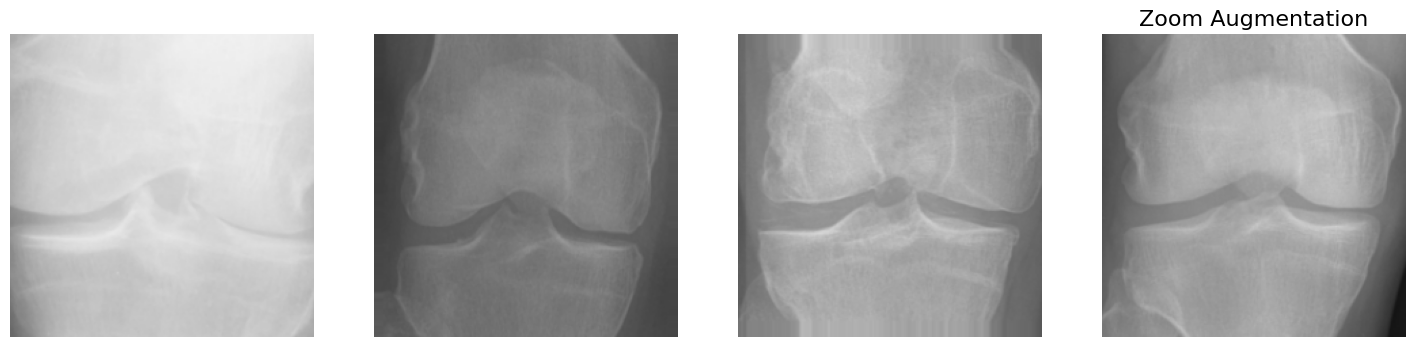

In [26]:
# Cell 9: Visualize zoom augmentation
# Zoom Augmentation: Randomly zooms in or out on the images within the specified range.
fig, rows = plt.subplots(1, 4, figsize=(18, 18))
plt.title("Zoom Augmentation", fontsize=16)
for row in rows:
    row.imshow(imagegen_zoom.__next__()[0][0].astype("uint8"))
    row.axis('off')
plt.show()


In [27]:
# Cell 10: Define horizontal flip augmentation
datagen_horizontal_flip = ImageDataGenerator(horizontal_flip=True)
imagegen_horizontal_flip = datagen_horizontal_flip.flow_from_directory(train_path, target_size=target_size, batch_size=1)


Found 5946 images belonging to 5 classes.


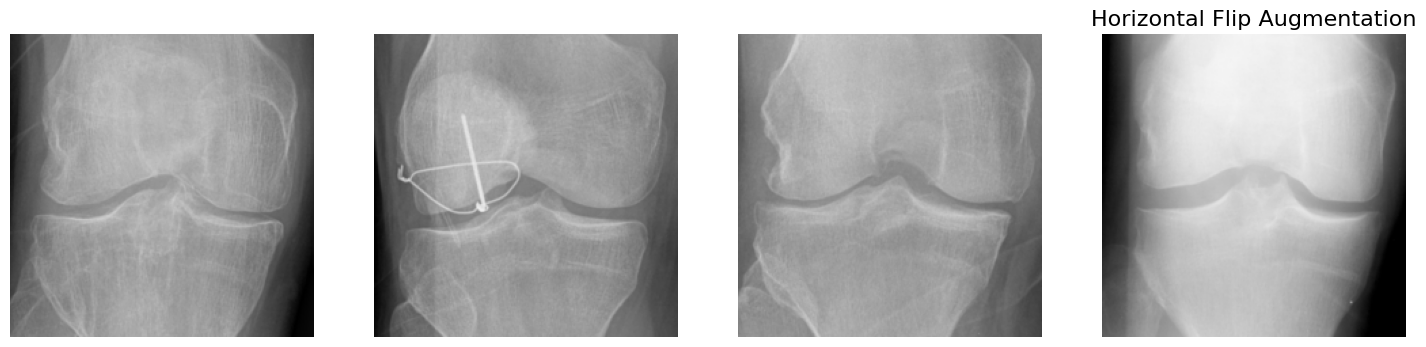

In [28]:
# Cell 11: Visualize horizontal flip augmentation
# Horizontal Flip Augmentation: Randomly flips the images horizontally.
fig, rows = plt.subplots(1, 4, figsize=(18, 18))
plt.title("Horizontal Flip Augmentation", fontsize=16)
for row in rows:
    row.imshow(imagegen_horizontal_flip.__next__()[0][0].astype("uint8"))
    row.axis('off')
plt.show()


In [29]:
# Cell 12: Define vertical flip augmentation
datagen_vertical_flip = ImageDataGenerator(vertical_flip=True)
imagegen_vertical_flip = datagen_vertical_flip.flow_from_directory(train_path, target_size=target_size, batch_size=1)


Found 5946 images belonging to 5 classes.


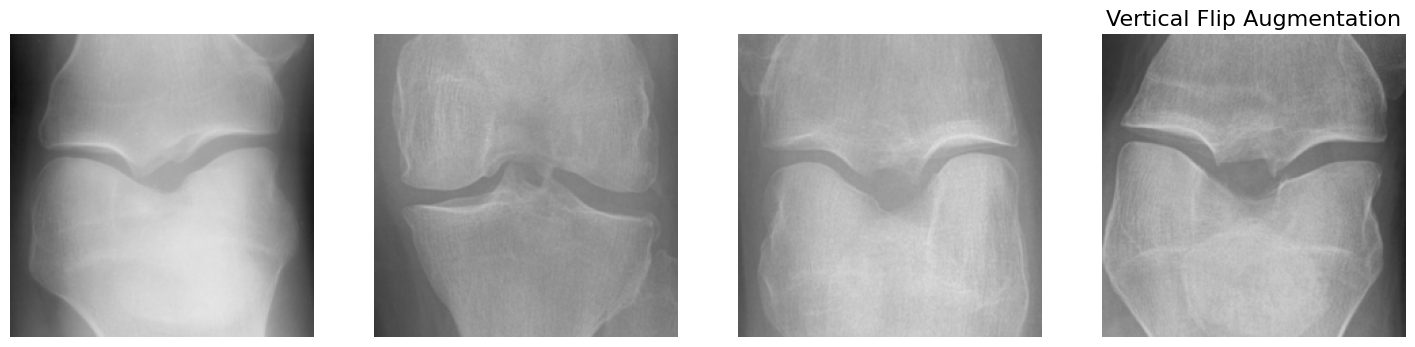

In [30]:
# Cell 13: Visualize vertical flip augmentation
# Vertical Flip Augmentation: Randomly flips the images vertically.
fig, rows = plt.subplots(1, 4, figsize=(18, 18))
plt.title("Vertical Flip Augmentation", fontsize=16)
for row in rows:
    row.imshow(imagegen_vertical_flip.__next__()[0][0].astype("uint8"))
    row.axis('off')
plt.show()


In [31]:
# Cell 14: Define rotation augmentation
datagen_rotation = ImageDataGenerator(rotation_range=40)
imagegen_rotation = datagen_rotation.flow_from_directory(train_path, target_size=target_size, batch_size=1)


Found 5946 images belonging to 5 classes.


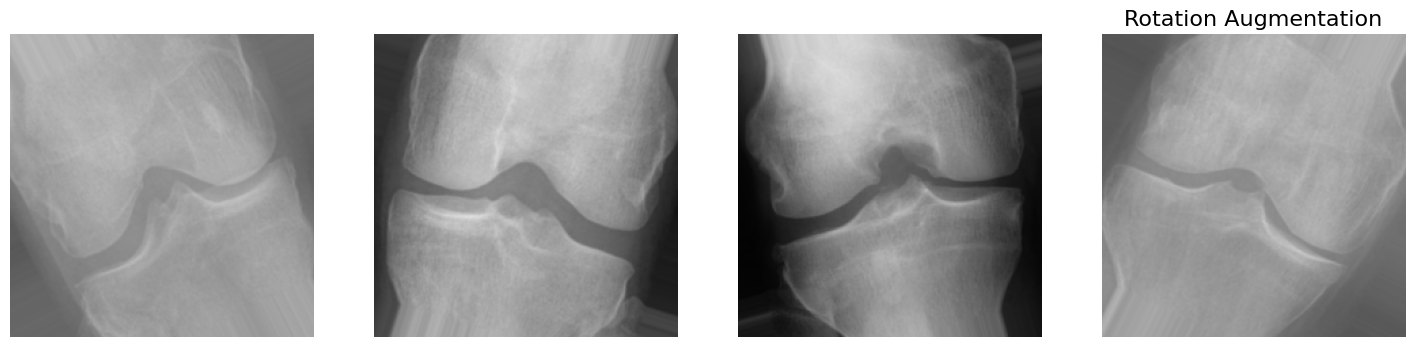

In [32]:
# Cell 15: Visualize rotation augmentation
# Rotation Augmentation: Randomly rotates the images within the specified range of degrees.
fig, rows = plt.subplots(1, 4, figsize=(18, 18))
plt.title("Rotation Augmentation", fontsize=16)
for row in rows:
    row.imshow(imagegen_rotation.__next__()[0][0].astype("uint8"))
    row.axis('off')
plt.show()


In [33]:
# Cell 16: Define shear augmentation
datagen_shear = ImageDataGenerator(shear_range=0.2)
imagegen_shear = datagen_shear.flow_from_directory(train_path, target_size=target_size, batch_size=1)


Found 5946 images belonging to 5 classes.


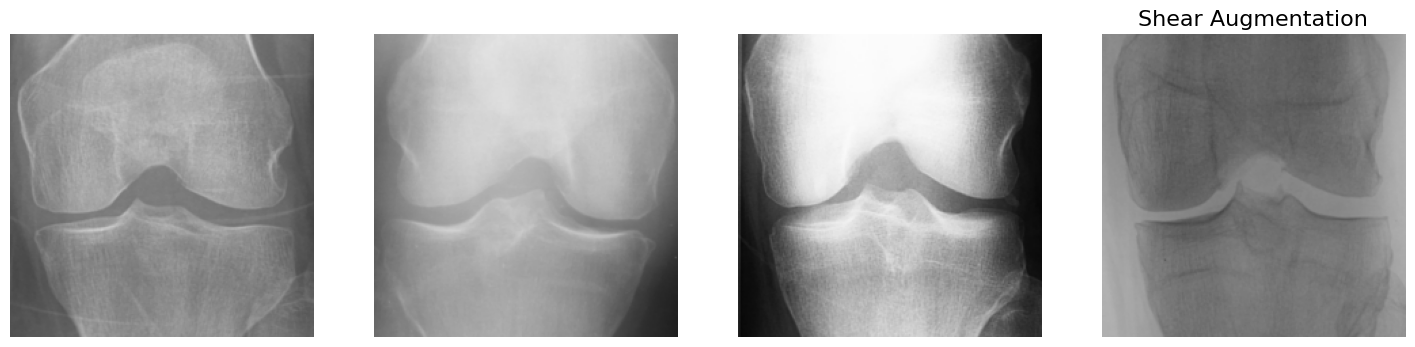

In [34]:
# Cell 17: Visualize shear augmentation
# Shear Augmentation: Randomly shears the images within the specified range of degrees.
fig, rows = plt.subplots(1, 4, figsize=(18, 18))
plt.title("Shear Augmentation", fontsize=16)
for row in rows:
    row.imshow(imagegen_shear.__next__()[0][0].astype("uint8"))
    row.axis('off')
plt.show()


In [5]:
# Cell 18: Define channel shift augmentation
datagen_channel_shift = ImageDataGenerator(channel_shift_range=150.0)
imagegen_channel_shift = datagen_channel_shift.flow_from_directory(train_path, target_size=target_size, batch_size=1)


Found 5946 images belonging to 5 classes.


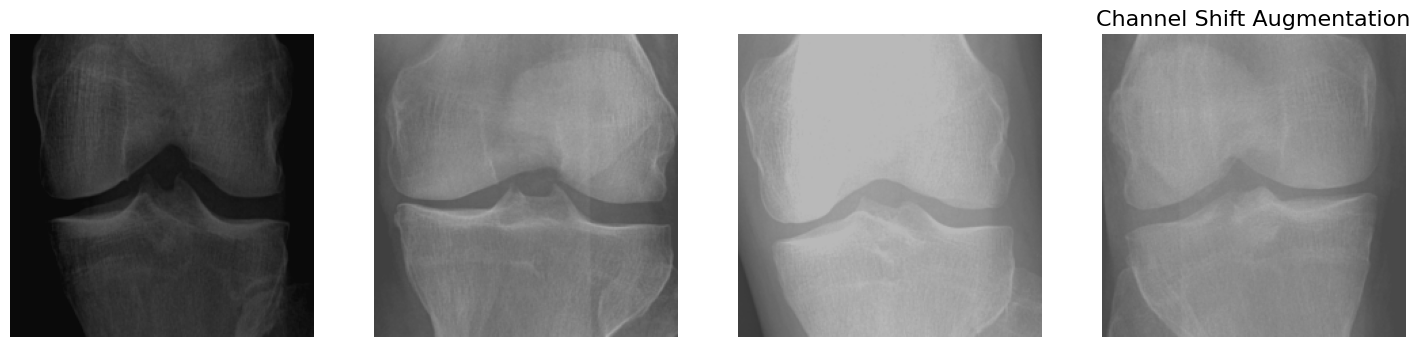

In [6]:
# Cell 19: Visualize channel shift augmentation
# Channel Shift Augmentation: Randomly shifts the color channels of the images by a specified range.
fig, rows = plt.subplots(1, 4, figsize=(18, 18))
plt.title("Channel Shift Augmentation", fontsize=16)
for row in rows:
    row.imshow(imagegen_channel_shift.__next__()[0][0].astype("uint8"))
    row.axis('off')
plt.show()


In [37]:
# Cell 20: Define fill mode augmentation
datagen_fill_mode = ImageDataGenerator(fill_mode='nearest')
imagegen_fill_mode = datagen_fill_mode.flow_from_directory(train_path, target_size=target_size, batch_size=1)


Found 5946 images belonging to 5 classes.


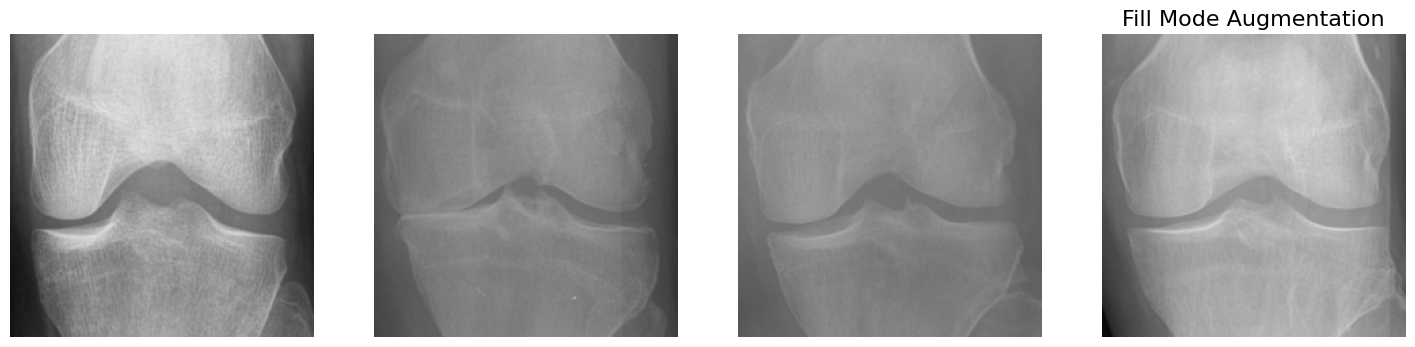

In [38]:
# Cell 21: Visualize fill mode augmentation
# Fill Mode Augmentation: Fills in new pixels created as a result of transformation.
fig, rows = plt.subplots(1, 4, figsize=(18, 18))
plt.title("Fill Mode Augmentation", fontsize=16)
for row in rows:
    row.imshow(imagegen_fill_mode.__next__()[0][0].astype("uint8"))
    row.axis('off')
plt.show()


In [39]:
y_train = train_generator.labels
y_val = valid_generator.labels

In [40]:
unique, counts = np.unique(y_train, return_counts=True)
print("Train ---> ", dict(zip(unique, counts)))

class_weights = compute_class_weight(
    class_weight="balanced", classes=np.unique(y_train), y=y_train
)
train_class_weights = dict(enumerate(class_weights))
print(train_class_weights)

Train --->  {np.int32(0): np.int64(2340), np.int32(1): np.int64(1073), np.int32(2): np.int64(1570), np.int32(3): np.int64(784), np.int32(4): np.int64(179)}
{0: np.float64(0.5082051282051282), 1: np.float64(1.1082945013979497), 2: np.float64(0.7574522292993631), 3: np.float64(1.5168367346938776), 4: np.float64(6.643575418994414)}
